# 06. Лабораторные панели маркеров


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт собирает сырые лабораторные панели в матрицу маркеров, пригодную для смешанной модели качества.

| | |
|---|---|
| **Данные** | `data/lab_report_2020.csv` … `data/lab_report_2023.csv`, `data/marker_map.csv` |
| **Цель** | Отфильтровать нестабильные и пустые вызовы, выровнять кодировку, посчитать call rate и индекс однородности |
| **Результат** | Числовая матрица `0/1/2/5` и карта маркеров по каналам; решение, какие образцы и маркеры оставлять в модели |


In [2]:
library(dplyr)
library(tidyr)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [3]:
threshold_equal <- 0.75
threshold_qc <- 0.75
min_callrate <- 0.85

lab_2020 <- read.csv("data/lab_report_2020.csv")
lab_2021 <- read.csv("data/lab_report_2021.csv")
lab_2022 <- read.csv("data/lab_report_2022.csv")
lab_2023 <- read.csv("data/lab_report_2023.csv")
marker_map <- read.csv("data/marker_map.csv")

raw <- bind_rows(lab_2020, lab_2021, lab_2022, lab_2023)


# 1. Характеристика сырых отчётов

Четыре годовых выгрузки лаборатории в длинном формате: образец × маркер × вызов. Повторяющиеся строки — повторные прогоны одной и той же пары.


In [4]:
summary(raw)


  sample_id         marker_name          allele1            allele2         
 Length:25248       Length:25248       Length:25248       Length:25248      
 Class :character   Class :character   Class :character   Class :character  
 Mode  :character   Mode  :character   Mode  :character   Mode  :character  
                                                                            
                                                                            
                                                                            
    qc_score           year     
 Min.   :0.0034   Min.   :2020  
 1st Qu.:0.7802   1st Qu.:2020  
 Median :0.8631   Median :2021  
 Mean   :0.8171   Mean   :2021  
 3rd Qu.:0.9209   3rd Qu.:2022  
 Max.   :0.9993   Max.   :2023  


In [5]:
raw %>%
  count(year) %>%
  knitr::kable(caption = "Число записей по годам")




Table: Число записей по годам

| year|    n|
|----:|----:|
| 2020| 6638|
| 2021| 6687|
| 2022| 6182|
| 2023| 5741|


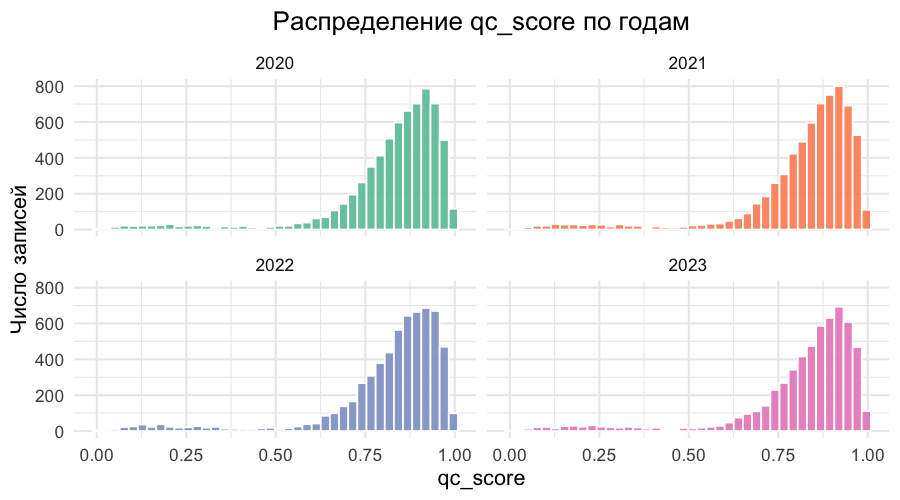

In [6]:
ggplot(raw, aes(x = qc_score, fill = factor(year))) +
  geom_histogram(bins = 40, color = "white", alpha = 0.9) +
  facet_wrap(~year, ncol = 2) +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Распределение qc_score по годам", x = "qc_score", y = "Число записей") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 2. Фильтрация вызовов

Оставляем маркеры, у которых нет доминирующего единственного вызова (`n_equals / n_calls ≤ 0.75`), и строки с `qc_score ≥ 0.75`. Для пары образец–маркер берём уникальную запись, пропуски кодируем как `--`.


In [7]:
filtered <- raw %>%
  group_by(marker_name, allele1, allele2) %>%
  mutate(n_equals = n()) %>%
  group_by(marker_name) %>%
  mutate(n_calls = n()) %>%
  filter(n_equals / n_calls <= threshold_equal) %>%
  ungroup() %>%
  filter(qc_score >= threshold_qc) %>%
  mutate(call = paste0(allele1, allele2)) %>%
  select(sample_id, marker_name, call) %>%
  distinct(sample_id, marker_name, .keep_all = TRUE) %>%
  pivot_wider(names_from = marker_name, values_from = call) %>%
  mutate(across(-sample_id, ~ ifelse(is.na(.), "--", as.character(.))))

n_raw_markers <- length(unique(raw$marker_name))
n_wide_markers <- ncol(filtered) - 1
c(
  samples = nrow(filtered),
  markers = n_wide_markers,
  raw_markers = n_raw_markers
)


    samples     markers raw_markers 
        220          48          48 


# 3. Выравнивание кодировки

Если гомозигота `BB` встречается чаще `AA`, пары меняются местами. Так мажорное состояние становится референсом `AA`, и матрица сравнивается между партиями.


In [8]:
flip_reference <- function(df) {
  marker_cols <- setdiff(names(df), "sample_id")
  for (col in marker_cols) {
    x <- df[[col]]
    n_aa <- sum(x == "AA", na.rm = TRUE)
    n_bb <- sum(x == "BB", na.rm = TRUE)
    if (n_bb > n_aa) {
      df[[col]] <- dplyr::case_when(
        x == "AA" ~ "BB",
        x == "BB" ~ "AA",
        TRUE ~ x
      )
    }
  }
  df
}

wide <- flip_reference(filtered)
wide$sample_id <- as.factor(wide$sample_id)
marker_cols <- setdiff(names(wide), "sample_id")
head(wide[, c("sample_id", marker_cols[1:6])])


# A tibble: 6 × 7
  sample_id M001  M002  M003  M004  M005  M006 
  <fct>     <chr> <chr> <chr> <chr> <chr> <chr>
1 S0002     AA    AA    AA    AA    AA    AB   
2 S0003     BB    BB    AA    --    AA    AB   
3 S0004     AA    AA    --    AB    AA    --   
4 S0007     BB    AB    AA    AB    AA    --   
5 S0008     AA    BB    AA    --    AB    AA   
6 S0009     AB    --    AA    AA    AB    AB   


# 4. Call rate и числовая кодировка

`AA → 0`, `AB → 1`, `BB → 2`, пропуск `-- → 5`. Call rate — доля непропущенных вызовов по маркеру и по образцу. Порог отсечения `0.85`.


In [9]:
encode_panel <- function(df, marker_cols) {
  mat <- as.matrix(df[, marker_cols])
  num <- matrix(5, nrow = nrow(mat), ncol = ncol(mat))
  num[mat == "AA"] <- 0
  num[mat == "AB" | mat == "BA"] <- 1
  num[mat == "BB"] <- 2
  colnames(num) <- marker_cols
  num
}

panel <- encode_panel(wide, marker_cols)
callrate_marker <- colMeans(panel != 5)
callrate_sample <- rowMeans(panel != 5)

keep_marker <- callrate_marker >= min_callrate
keep_sample <- callrate_sample >= min_callrate
panel_qc <- panel[keep_sample, keep_marker, drop = FALSE]
wide_qc <- wide[keep_sample, c("sample_id", names(keep_marker)[keep_marker]), drop = FALSE]

data.frame(
  metric = c("callrate_marker_mean", "callrate_sample_mean", "markers_kept", "samples_kept"),
  value = c(
    mean(callrate_marker),
    mean(callrate_sample),
    sum(keep_marker),
    sum(keep_sample)
  )
)


                metric      value
1 callrate_marker_mean   0.842803
2 callrate_sample_mean   0.842803
3         markers_kept  42.000000
4         samples_kept 144.000000


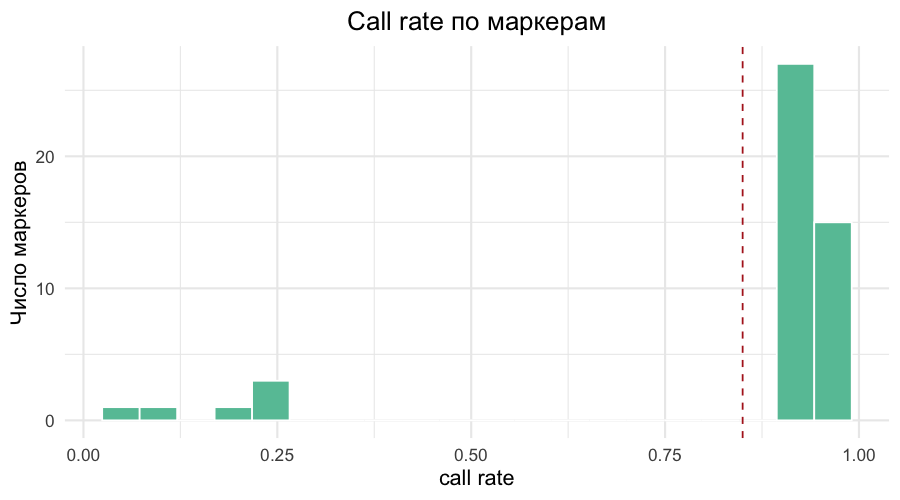

In [10]:
cr_marker <- data.frame(marker = names(callrate_marker), callrate = as.numeric(callrate_marker))
ggplot(cr_marker, aes(x = callrate)) +
  geom_histogram(bins = 20, fill = "#66C2A5", color = "white") +
  geom_vline(xintercept = min_callrate, linetype = "dashed", color = "firebrick") +
  labs(title = "Call rate по маркерам", x = "call rate", y = "Число маркеров") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


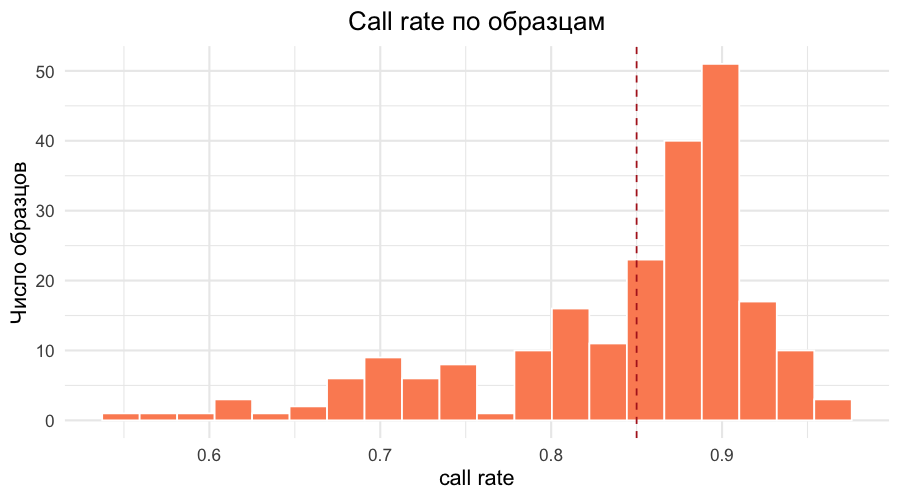

In [11]:
cr_sample <- data.frame(sample_id = wide$sample_id, callrate = as.numeric(callrate_sample))
ggplot(cr_sample, aes(x = callrate)) +
  geom_histogram(bins = 20, fill = "#FC8D62", color = "white") +
  geom_vline(xintercept = min_callrate, linetype = "dashed", color = "firebrick") +
  labs(title = "Call rate по образцам", x = "call rate", y = "Число образцов") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 5. Карта маркеров

Маркеры с каналом `0` отбрасываются как служебные. Оставшиеся выстраиваются в том же порядке, что и столбцы матрицы.


In [12]:
map_clean <- marker_map %>%
  filter(channel != 0) %>%
  filter(name %in% colnames(panel_qc)) %>%
  arrange(name)

panel_aligned <- panel_qc[, map_clean$name, drop = FALSE]
map_clean$number <- seq_len(nrow(map_clean))

knitr::kable(head(map_clean, 10), caption = "Карта маркеров после очистки")
c(markers_on_map = nrow(map_clean), matrix_cols = ncol(panel_aligned))




Table: Карта маркеров после очистки

|name | channel| position| number|
|:----|-------:|--------:|------:|
|M001 |       1|      137|      1|
|M002 |       2|      174|      2|
|M003 |       3|      211|      3|
|M004 |       4|      248|      4|
|M006 |       6|      322|      5|
|M008 |       8|      396|      6|
|M009 |       1|      433|      7|
|M010 |       2|      470|      8|
|M011 |       3|      507|      9|
|M012 |       4|      544|     10|


markers_on_map    matrix_cols 
            40             40 


# 6. Индекс однородности

Для каждого образца считаем долю гомозиготных вызовов (`0` или `2`) среди успешных. Индекс — относительное отклонение от среднего по панели: положительное значение значит, что изделие однороднее типичного.


In [13]:
hom_mat <- (panel_aligned == 0) | (panel_aligned == 2)
called_mat <- panel_aligned != 5
hom_count <- rowSums(hom_mat)
called <- rowSums(called_mat)
hom_rate <- hom_count / pmax(called, 1)
avg_hom <- mean(hom_rate)
purity <- data.frame(
  sample_id = wide_qc$sample_id,
  hom_rate = hom_rate,
  purity_index = (hom_rate - avg_hom) / avg_hom
)

summary(purity$purity_index)


    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.38732 -0.07836 -0.01541  0.00000  0.08921  0.30705 


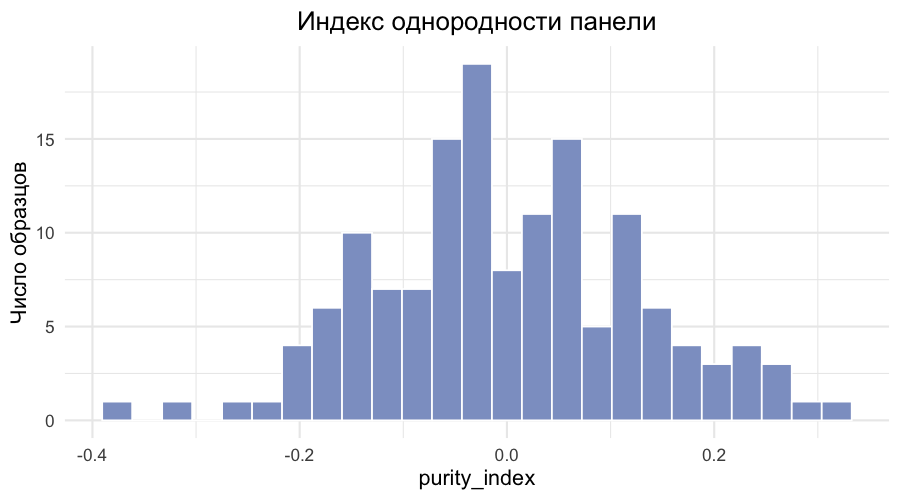

In [14]:
ggplot(purity, aes(x = purity_index)) +
  geom_histogram(bins = 25, fill = "#8DA0CB", color = "white") +
  labs(title = "Индекс однородности панели", x = "purity_index", y = "Число образцов") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 7. Матрица для модели

Строка — образец, столбцы склеены в одну строку кодов. Пропуски остаются `5`, чтобы смешанная модель отличала их от гетерозиготы.


In [15]:
encoded <- data.frame(
  sample_id = wide_qc$sample_id,
  combined = apply(panel_aligned, 1, paste0, collapse = ""),
  stringsAsFactors = FALSE
)
head(encoded, 8)
nchar(encoded$combined[1])


  sample_id                                 combined
1     S0043 1010000001111111120011020151002005012211
2     S0044 1001150101100201110020101010110101111511
3     S0046 0110001001100501000201110000151110111000
4     S0048 0102105100121121510110100111102010001001
5     S0049 0001001151010002221100011051011100101200
6     S0052 0001000200200001021010510010120100111000
7     S0053 0001001000010110500110001001120015010002
8     S0059 0111011511000020111201110001012000210011


[1] 40


# Заключение

Сырые годовые отчёты нельзя подавать в модель как есть: часть маркеров почти мономорфна, часть вызовов с низким `qc_score`, кодировка `AA`/`BB` плавает между партиями.

После порогов `qc_score ≥ 0.75`, нестабильности вызова и `call rate ≥ 0.85` остаётся выровненная матрица `0/1/2/5` и карта по каналам. Индекс однородности показывает, какие образцы выбиваются из типичного профиля панели — их стоит смотреть отдельно, а не смешивать с основным контуром оценки.
